# Supervised Learning Model Evaluation Lab

Complete the exercises below to solidify your knowledge and understanding of supervised learning model evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

## Regression Model Evaluation

In [2]:
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
data = pd.read_csv('housing.csv', header=None, delimiter=r"\s+", names=column_names)

In [3]:
"""
CRIM - per capita crime rate by town
ZN - proportion of residential land zoned for lots over 25,000 sq.ft.
INDUS - proportion of non-retail business acres per town.
CHAS - Charles River dummy variable (1 if tract bounds river; 0 otherwise)
NOX - nitric oxides concentration (parts per 10 million)
RM - average number of rooms per dwelling
AGE - proportion of owner-occupied units built prior to 1940
DIS - weighted distances to five Boston employment centres
RAD - index of accessibility to radial highways
TAX - full-value property-tax rate per $10,000
PTRATIO - pupil-teacher ratio by town
B - 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town
LSTAT - % lower status of the population
MEDV - Median value of owner-occupied homes in $1000's"""

"\nCRIM - per capita crime rate by town\nZN - proportion of residential land zoned for lots over 25,000 sq.ft.\nINDUS - proportion of non-retail business acres per town.\nCHAS - Charles River dummy variable (1 if tract bounds river; 0 otherwise)\nNOX - nitric oxides concentration (parts per 10 million)\nRM - average number of rooms per dwelling\nAGE - proportion of owner-occupied units built prior to 1940\nDIS - weighted distances to five Boston employment centres\nRAD - index of accessibility to radial highways\nTAX - full-value property-tax rate per $10,000\nPTRATIO - pupil-teacher ratio by town\nB - 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town\nLSTAT - % lower status of the population\nMEDV - Median value of owner-occupied homes in $1000's"

In [4]:
data

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,393.45,6.48,22.0


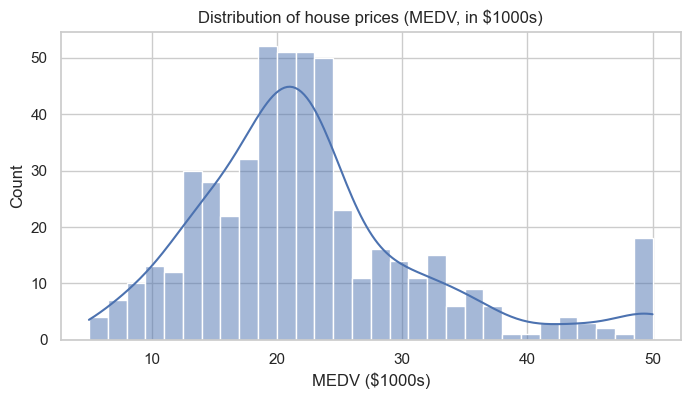

In [5]:
plt.figure(figsize=(8, 4))
sns.histplot(data['MEDV'], bins=30, kde=True)
plt.title('Distribution of house prices (MEDV, in $1000s)')
plt.xlabel('MEDV ($1000s)')
plt.show()

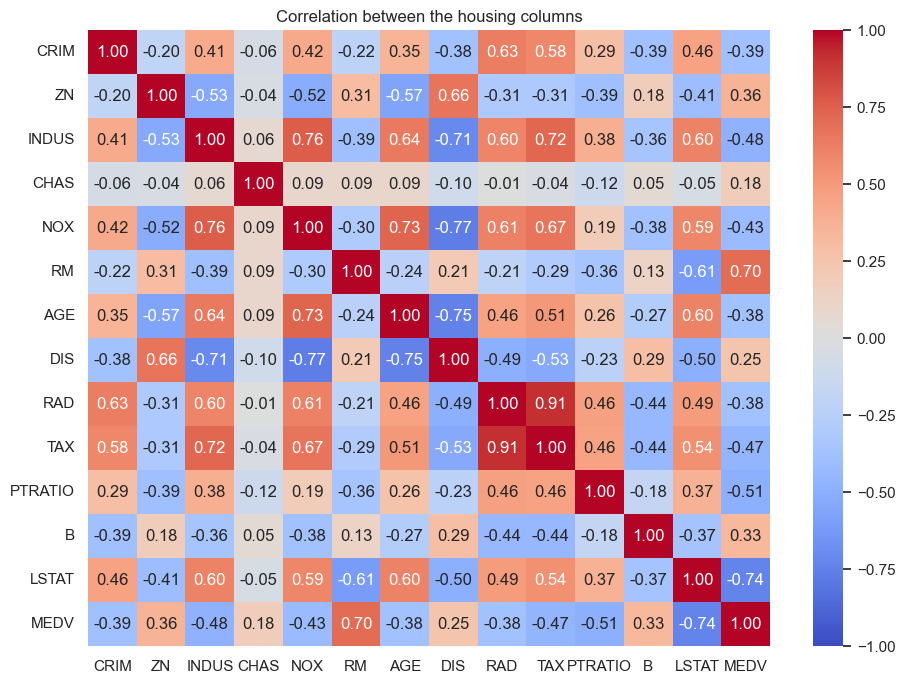

In [6]:
plt.figure(figsize=(11, 8))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between the housing columns')
plt.show()

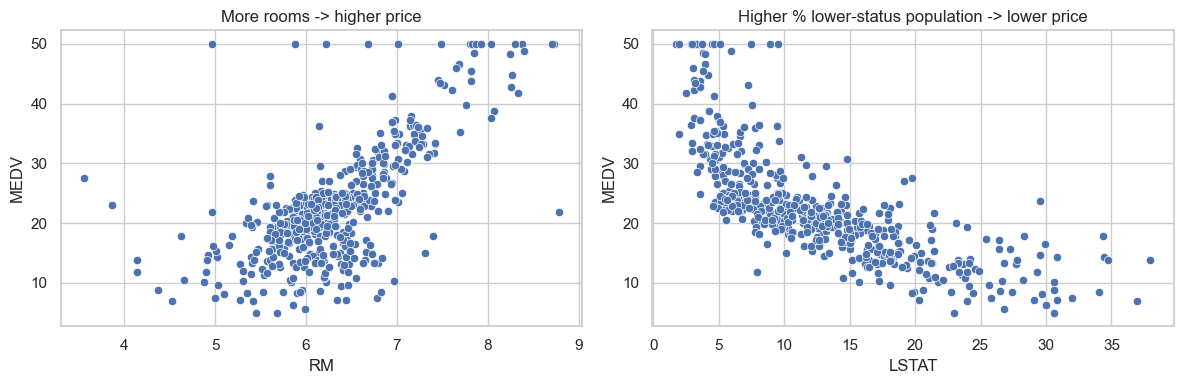

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=data, x='RM', y='MEDV', ax=axes[0])
axes[0].set_title('More rooms -> higher price')
sns.scatterplot(data=data, x='LSTAT', y='MEDV', ax=axes[1])
axes[1].set_title('Higher % lower-status population -> lower price')
plt.tight_layout()
plt.show()

## 1. Split this data set into training (80%) and testing (20%) sets.

The `MEDV` field represents the median value of owner-occupied homes (in $1000's) and is the target variable that we will want to predict.

In [8]:
# Your code here :

from sklearn.model_selection import train_test_split

X = data.drop('MEDV', axis=1)
y = data['MEDV']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(404, 13) (102, 13)


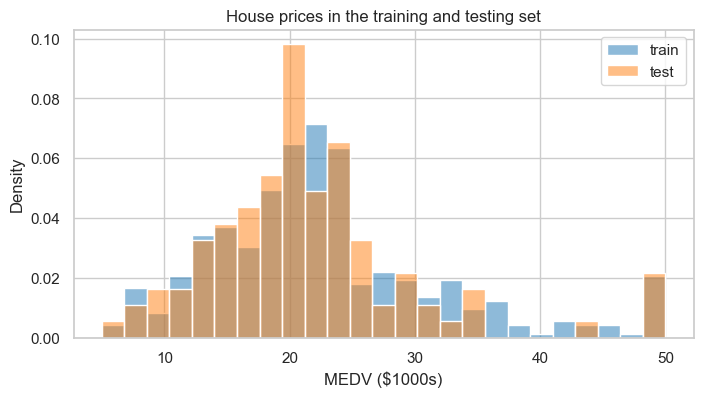

In [9]:
plt.figure(figsize=(8, 4))
sns.histplot(y_train, color='tab:blue', label='train', stat='density', alpha=0.5, bins=25)
sns.histplot(y_test, color='tab:orange', label='test', stat='density', alpha=0.5, bins=25)
plt.title('House prices in the training and testing set')
plt.xlabel('MEDV ($1000s)')
plt.legend()
plt.show()

## 2. Train a `LinearRegression` model on this data set and generate predictions on both the training and the testing set.

In [10]:
# Your code here :

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

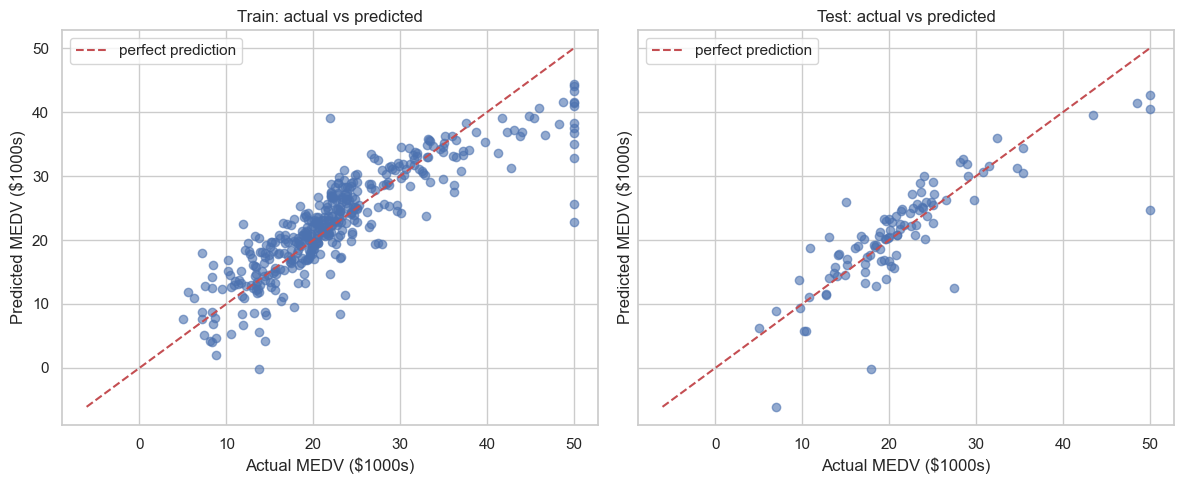

In [11]:
lo = min(y.min(), pred_train.min(), pred_test.min())
hi = max(y.max(), pred_train.max(), pred_test.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (name, y_true, y_hat) in zip(axes, [('Train', y_train, pred_train), ('Test', y_test, pred_test)]):
    ax.scatter(y_true, y_hat, alpha=0.6)
    ax.plot([lo, hi], [lo, hi], 'r--', label='perfect prediction')
    ax.set_title(f'{name}: actual vs predicted')
    ax.set_xlabel('Actual MEDV ($1000s)')
    ax.set_ylabel('Predicted MEDV ($1000s)')
    ax.legend()
plt.tight_layout()
plt.show()

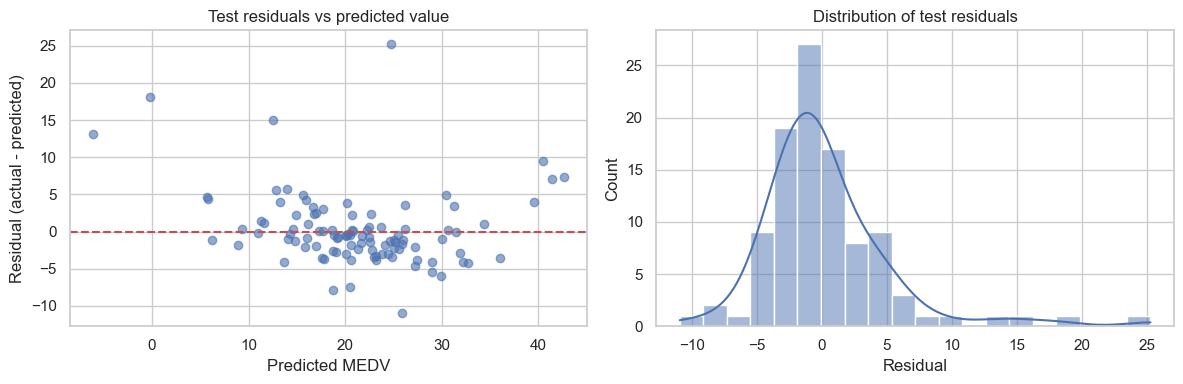

In [12]:
residuals_test = y_test - pred_test

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pred_test, residuals_test, alpha=0.6)
axes[0].axhline(0, color='r', linestyle='--')
axes[0].set_title('Test residuals vs predicted value')
axes[0].set_xlabel('Predicted MEDV')
axes[0].set_ylabel('Residual (actual - predicted)')

sns.histplot(residuals_test, bins=20, kde=True, ax=axes[1])
axes[1].set_title('Distribution of test residuals')
axes[1].set_xlabel('Residual')
plt.tight_layout()
plt.show()

## 3. Calculate and print R-squared for both the training and the testing set.

In [13]:
# Your code here :

from sklearn.metrics import r2_score

print('R2 train:', r2_score(y_train, pred_train))
print('R2 test :', r2_score(y_test, pred_test))

R2 train: 0.7508856358979673
R2 test : 0.6687594935356296


## 4. Calculate and print mean squared error for both the training and the testing set.

In [14]:
# Your code here :

from sklearn.metrics import mean_squared_error

print('MSE train:', mean_squared_error(y_train, pred_train))
print('MSE test :', mean_squared_error(y_test, pred_test))

MSE train: 21.641412753226312
MSE test : 24.29111947497369


## 5. Calculate and print mean absolute error for both the training and the testing set.

In [15]:
# Your code here :

from sklearn.metrics import mean_absolute_error

print('MAE train:', mean_absolute_error(y_train, pred_train))
print('MAE test :', mean_absolute_error(y_test, pred_test))

MAE train: 3.314771626783228
MAE test : 3.1890919658878603


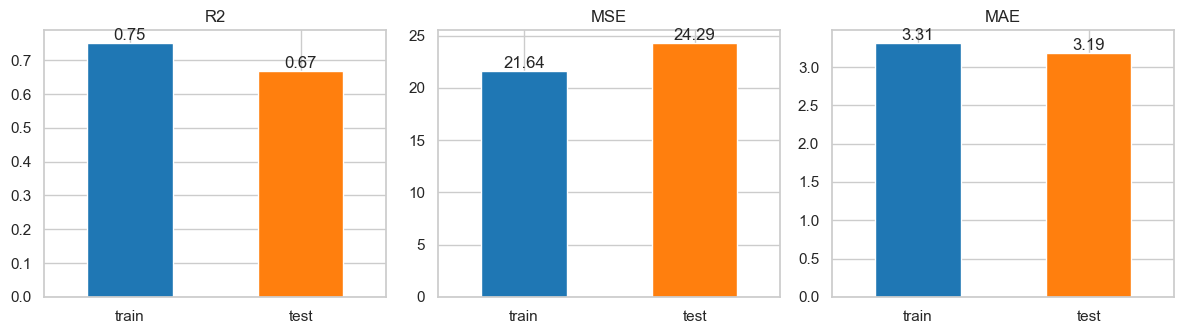

In [16]:
metrics = pd.DataFrame({
    'R2':  [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
    'MSE': [mean_squared_error(y_train, pred_train), mean_squared_error(y_test, pred_test)],
    'MAE': [mean_absolute_error(y_train, pred_train), mean_absolute_error(y_test, pred_test)],
}, index=['train', 'test'])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, metrics.columns):
    metrics[col].plot(kind='bar', ax=ax, color=['tab:blue', 'tab:orange'], rot=0)
    ax.set_title(col)
    ax.bar_label(ax.containers[0], fmt='%.2f')
plt.tight_layout()
plt.show()

The model explains about 75% of the price variation on the training set and 67% on the test set. The drop from train to test is a sign of mild overfitting. The test MSE (24.3) is higher than the train MSE (21.6), which suggests a few houses have large errors (the biggest test error is about $25,000), while the MAE is similar in both sets (about 3.2 to 3.3, so roughly $3,200 off on average). The model is reasonable, but a linear model cannot capture everything in this data.

## Classification Model Evaluation

In [17]:
from sklearn.datasets import load_iris
data = load_iris()

In [18]:
print(data.DESCR)
column_names = data.feature_names
df = pd.DataFrame(data['data'], columns=column_names)
df
target = pd.DataFrame(data.target)
data.keys()
data['target_names']

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

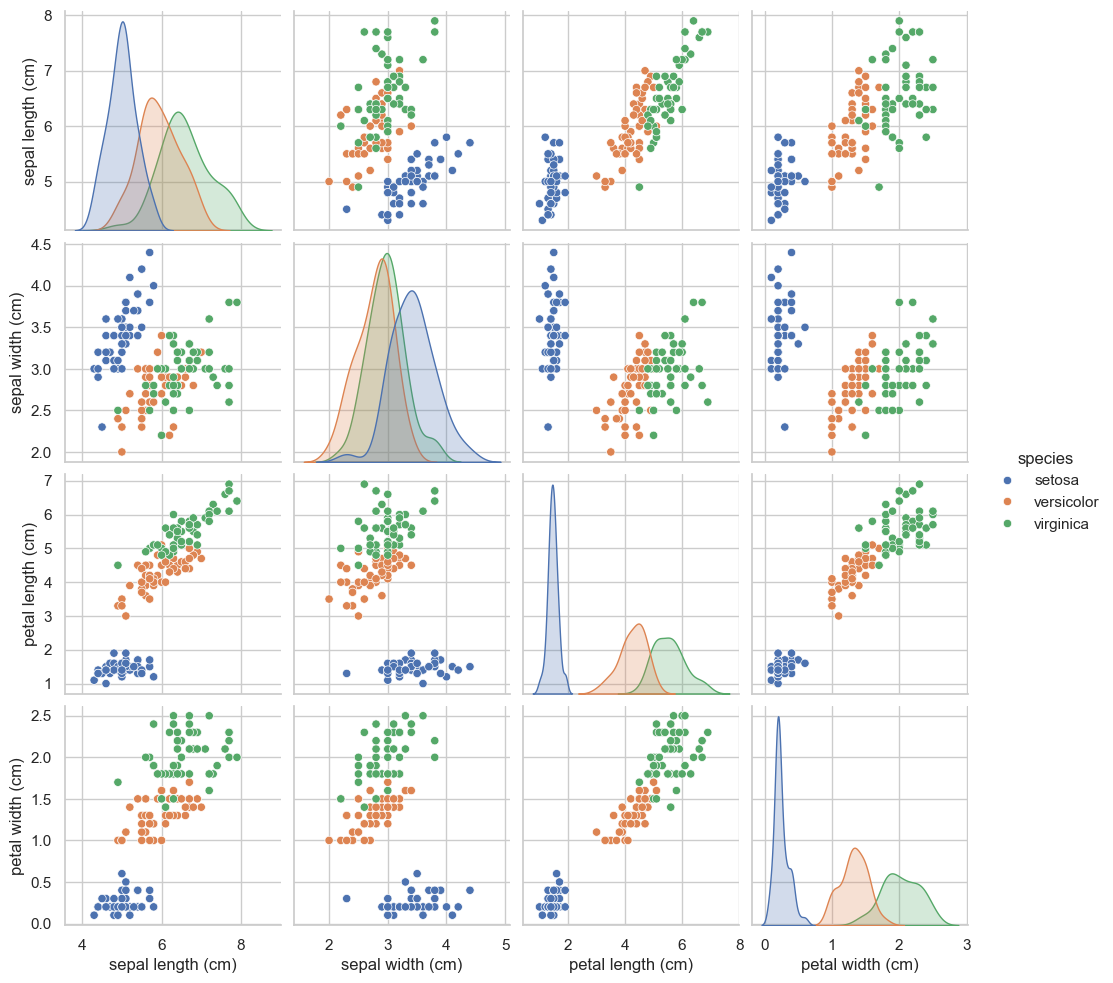

In [19]:
iris_plot = df.copy()
iris_plot['species'] = data.target_names[data.target]

sns.pairplot(iris_plot, hue='species')
plt.show()

In [20]:
column_names = data.feature_names

In [21]:
df = pd.DataFrame(data['data'],columns=column_names)

In [22]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [23]:
target = pd.DataFrame(data.target)

In [24]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [25]:
data['target_names']

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

## 6. Split this data set into training (80%) and testing (20%) sets.

The `class` field represents the type of flower and is the target variable that we will want to predict.

In [26]:
# Your code here :

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    df, target[0], test_size=0.2, random_state=42, stratify=target[0])
print(X_train_iris.shape, X_test_iris.shape)

(120, 4) (30, 4)


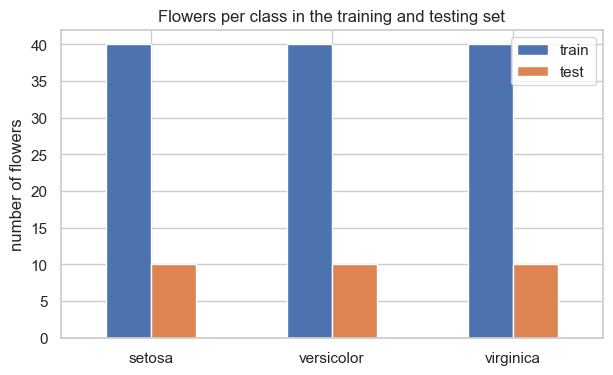

In [27]:
split_counts = pd.DataFrame({'train': y_train_iris.value_counts().sort_index(),
                             'test': y_test_iris.value_counts().sort_index()})
split_counts.index = data.target_names

split_counts.plot(kind='bar', rot=0, figsize=(7, 4))
plt.title('Flowers per class in the training and testing set')
plt.ylabel('number of flowers')
plt.show()

## 7. Train a `LogisticRegression` model on this data set and generate predictions on both the training and the testing set.

In [28]:
# Your code here :

from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=200)
log_model.fit(X_train_iris, y_train_iris)

pred_train_iris = log_model.predict(X_train_iris)
pred_test_iris = log_model.predict(X_test_iris)

## 8. Calculate and print the accuracy score for both the training and the testing set.

In [29]:
# Your code here :

from sklearn.metrics import accuracy_score

print('accuracy train:', accuracy_score(y_train_iris, pred_train_iris))
print('accuracy test :', accuracy_score(y_test_iris, pred_test_iris))

accuracy train: 0.975
accuracy test : 0.9666666666666667


## 9. Calculate and print the balanced accuracy score for both the training and the testing set.

In [30]:
# Your code here :

from sklearn.metrics import balanced_accuracy_score

print('balanced accuracy train:', balanced_accuracy_score(y_train_iris, pred_train_iris))
print('balanced accuracy test :', balanced_accuracy_score(y_test_iris, pred_test_iris))

balanced accuracy train: 0.975
balanced accuracy test : 0.9666666666666667


## 10. Calculate and print the precision score for both the training and the testing set.

In [31]:
# Your code here :

from sklearn.metrics import precision_score

print('precision train:', precision_score(y_train_iris, pred_train_iris, average='macro'))
print('precision test :', precision_score(y_test_iris, pred_test_iris, average='macro'))

precision train: 0.9751928288513655
precision test : 0.9696969696969697


## 11. Calculate and print the recall score for both the training and the testing set.

In [32]:
# Your code here :

from sklearn.metrics import recall_score

print('recall train:', recall_score(y_train_iris, pred_train_iris, average='macro'))
print('recall test :', recall_score(y_test_iris, pred_test_iris, average='macro'))

recall train: 0.975
recall test : 0.9666666666666667


## 12. Calculate and print the F1 score for both the training and the testing set.

In [33]:
# Your code here :

from sklearn.metrics import f1_score

print('F1 train:', f1_score(y_train_iris, pred_train_iris, average='macro'))
print('F1 test :', f1_score(y_test_iris, pred_test_iris, average='macro'))

F1 train: 0.974996093139553
F1 test : 0.9665831244778612


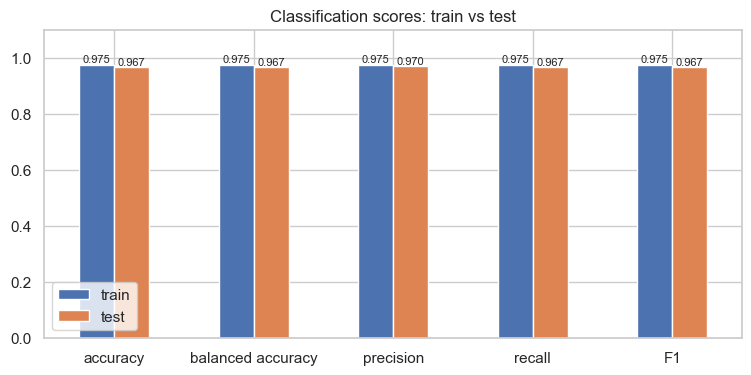

In [34]:
scores = pd.DataFrame({
    'accuracy': [accuracy_score(y_train_iris, pred_train_iris), accuracy_score(y_test_iris, pred_test_iris)],
    'balanced accuracy': [balanced_accuracy_score(y_train_iris, pred_train_iris), balanced_accuracy_score(y_test_iris, pred_test_iris)],
    'precision': [precision_score(y_train_iris, pred_train_iris, average='macro'), precision_score(y_test_iris, pred_test_iris, average='macro')],
    'recall': [recall_score(y_train_iris, pred_train_iris, average='macro'), recall_score(y_test_iris, pred_test_iris, average='macro')],
    'F1': [f1_score(y_train_iris, pred_train_iris, average='macro'), f1_score(y_test_iris, pred_test_iris, average='macro')],
}, index=['train', 'test']).T

ax = scores.plot(kind='bar', rot=0, figsize=(9, 4), ylim=(0, 1.1))
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=8)
plt.title('Classification scores: train vs test')
plt.show()

## 13. Generate confusion matrices for both the training and the testing set.

In [35]:
# Your code here :

from sklearn.metrics import confusion_matrix

print('train:')
print(confusion_matrix(y_train_iris, pred_train_iris))
print('test:')
print(confusion_matrix(y_test_iris, pred_test_iris))

train:
[[40  0  0]
 [ 0 38  2]
 [ 0  1 39]]
test:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


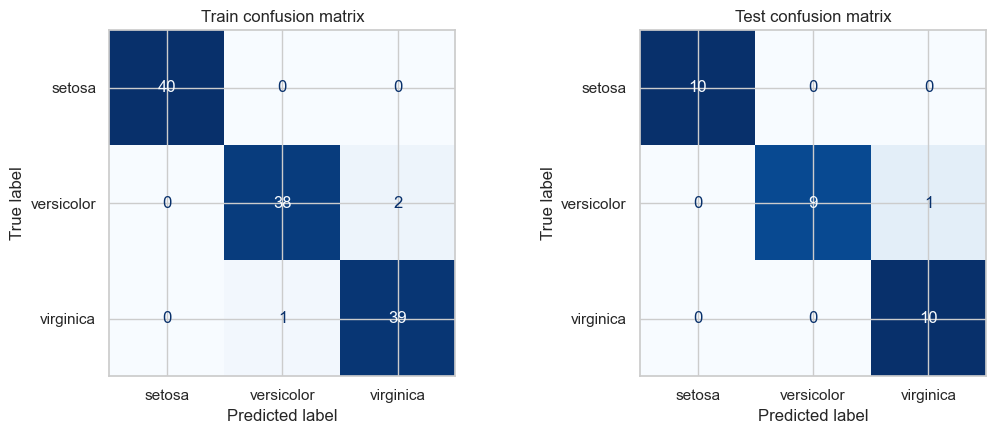

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, y_true, y_hat) in zip(axes, [('Train', y_train_iris, pred_train_iris), ('Test', y_test_iris, pred_test_iris)]):
    ConfusionMatrixDisplay.from_predictions(y_true, y_hat, display_labels=data.target_names,
                                            cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'{name} confusion matrix')
plt.tight_layout()
plt.show()

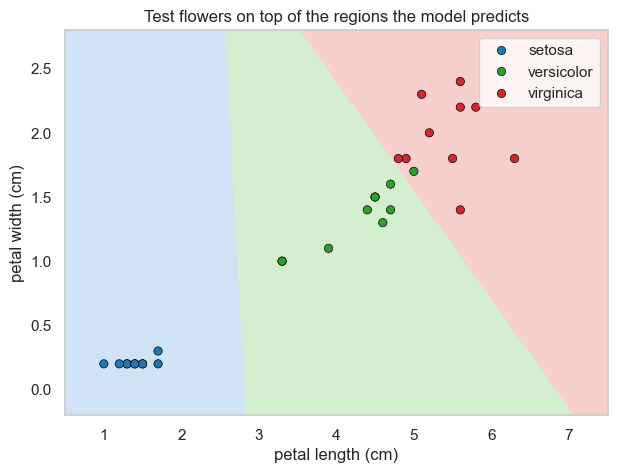

In [ ]:
# For the drawing only: a small model that uses just the 2 petal features
cols = ['petal length (cm)', 'petal width (cm)']
log_2d = LogisticRegression(max_iter=200).fit(X_train_iris[cols], y_train_iris)

colors = {'setosa': 'tab:blue', 'versicolor': 'tab:green', 'virginica': 'tab:red'}

# a grid of points covering the plot; the model predicts a class for every point
xx, yy = np.meshgrid(np.linspace(0.5, 7.5, 300), np.linspace(-0.2, 2.8, 300))
grid = pd.DataFrame({cols[0]: xx.ravel(), cols[1]: yy.ravel()})
zz = log_2d.predict(grid).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 5))
ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], colors=['#cfe3f5', '#d4efd0', '#f7d0cd'])
sns.scatterplot(x=X_test_iris[cols[0]], y=X_test_iris[cols[1]],
                hue=data.target_names[y_test_iris.to_numpy()], hue_order=list(colors),
                palette=colors, edgecolor='black', ax=ax)
ax.set_xlabel(cols[0])
ax.set_ylabel(cols[1])
ax.set_title('Test flowers on top of the regions the model predicts')
plt.show()

The logistic regression performs very well on iris: 97.5% accuracy on the training set and 96.7% on the test set. Balanced accuracy equals accuracy because the three classes have the same size. The only mistakes are between versicolor and virginica, which overlap in the plots; setosa is always predicted correctly. The small gap between train and test shows that the model is not overfitting.

## Bonus: For each of the data sets in this lab, try training with some of the other models you have learned about, recalculate the evaluation metrics, and compare to determine which models perform best on each data set.

In [38]:
# Have fun here !

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree (no limit)': DecisionTreeRegressor(random_state=42),
    'Decision Tree (depth 5)': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'KNN': KNeighborsRegressor(),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    rows.append({'model': name,
                 'R2 train': r2_score(y_train, p_tr), 'R2 test': r2_score(y_test, p_te),
                 'MSE test': mean_squared_error(y_test, p_te),
                 'MAE test': mean_absolute_error(y_test, p_te)})
results_reg = pd.DataFrame(rows).round(3)
results_reg

,model,R2 train,R2 test,MSE test,MAE test
0,Linear Regression,0.751,0.669,24.291,3.189
1,Decision Tree (no limit),1.000,0.848,11.143,2.528
2,Decision Tree (depth 5),0.919,0.883,8.554,2.308
3,Random Forest,0.977,0.890,8.074,2.044
4,KNN,0.684,0.647,25.860,3.664


In [39]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=200),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
}

rows = []
for name, m in models.items():
    m.fit(X_train_iris, y_train_iris)
    p_tr, p_te = m.predict(X_train_iris), m.predict(X_test_iris)
    rows.append({'model': name,
                 'accuracy train': accuracy_score(y_train_iris, p_tr),
                 'accuracy test': accuracy_score(y_test_iris, p_te),
                 'F1 test': f1_score(y_test_iris, p_te, average='macro')})
pd.DataFrame(rows).round(3)

,model,accuracy train,accuracy test,F1 test
0,Logistic Regression,0.975,0.967,0.967
1,Decision Tree,1.000,0.933,0.933
2,Random Forest,1.000,0.900,0.900
3,KNN,0.967,1.000,1.000


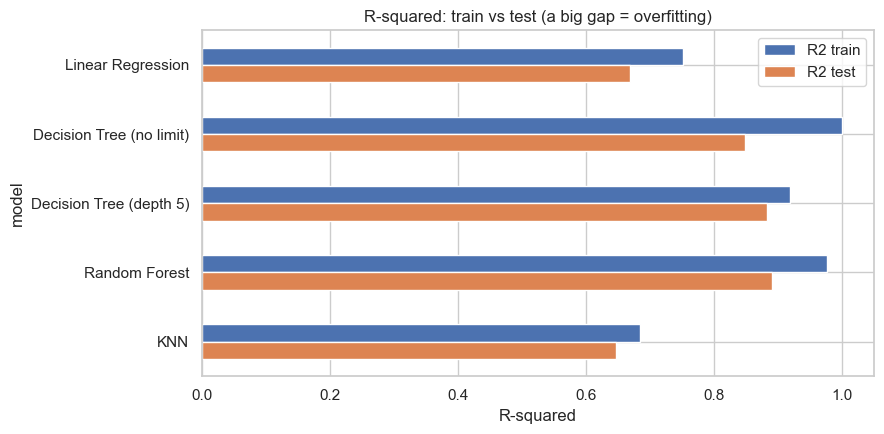

In [40]:
results_reg.set_index('model')[['R2 train', 'R2 test']].plot(kind='barh', figsize=(9, 4.5))
plt.title('R-squared: train vs test (a big gap = overfitting)')
plt.xlabel('R-squared')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [41]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=200),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
}

rows = []
for name, m in models.items():
    m.fit(X_train_iris, y_train_iris)
    p_tr, p_te = m.predict(X_train_iris), m.predict(X_test_iris)
    rows.append({'model': name,
                 'accuracy train': accuracy_score(y_train_iris, p_tr),
                 'accuracy test': accuracy_score(y_test_iris, p_te),
                 'F1 test': f1_score(y_test_iris, p_te, average='macro')})
results_clf = pd.DataFrame(rows).round(3)
results_clf

,model,accuracy train,accuracy test,F1 test
0,Logistic Regression,0.975,0.967,0.967
1,Decision Tree,1.000,0.933,0.933
2,Random Forest,1.000,0.900,0.900
3,KNN,0.967,1.000,1.000


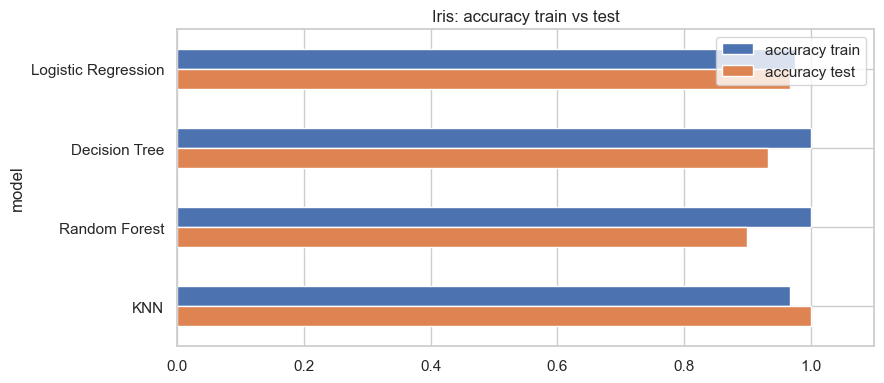

In [42]:
results_clf.set_index('model')[['accuracy train', 'accuracy test']].plot(kind='barh', figsize=(9, 4), xlim=(0, 1.1))
plt.title('Iris: accuracy train vs test')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Housing: the Random Forest is the best model (test R2 0.893, MAE 2.04), followed by the Decision Tree with max_depth=5. The unlimited Decision Tree has a perfect training score (R2 = 1.0) but a much lower test R2 (0.757), which means it memorised the training data (overfitting). KNN is the worst; it works with distances and I did not scale the features, so large-valued columns dominate. Linear Regression is in between.

Iris: all models score between 90% and 100% on the test set. The test set has only 30 flowers, so one flower is 3.3 percentage points; differences between the models are therefore mostly noise, and I would not say KNN is truly better than the others even though it scored 100%.